# code_131 · Residual correction and differentiable mechanical closure

**Book:** section 25.5. A self-contained scientific-learning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_25_GUIDE.md), [run evidence](../CHAPTER_25_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_131).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2931;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2931


<a id="multifidelity-contract"></a>
 ## Mechanics and learned corrections have distinct responsibilities
 A Dirichlet axial bar satisfies −(k*u')'=f on[0,1]. Inputs are stiffness slope a, material modifier b, load amplitude p and second-mode load coefficient c. Generate32 source, eight development and sixteen final parameter cases within declared ranges, plus sixteen changed-support cases with larger slope/modifier. Fine finite-volume solves use63 interior cells, coarse solves12. The coarse model omits a known generating spatial stiffness modulation. Compare coarse interpolation, data-only multioutput Ridge, residual-correction Ridge and a differentiable two-parameter positive-conductance closure on the coarse mesh. Ridge alpha is chosen separately from0.001/0.1/10 using development cases; the closure gets1,000 fixed Adam updates at0.03 with no final retuning. High-fidelity source fields are fit labels; final/shifted fine solutions are assessment only. The full coarse simulation is available at inference.


,model,source_MSE,development_MSE,final_MSE,changed_support_MSE
0,Coarse solver,1.416775e-05,1.273570e-05,1.356100e-05,1.318446e-05
1,Data-only Ridge,2.265227e-09,2.129987e-08,2.924282e-08,2.191876e-05
2,Residual Ridge,5.855266e-11,3.282015e-09,8.668150e-09,6.071468e-08
3,Learned mechanical closure,8.425599e-08,6.606445e-08,8.110596e-08,1.124600e-07


Fitted closure: [0.35744678851717, 0.1365405082343037]


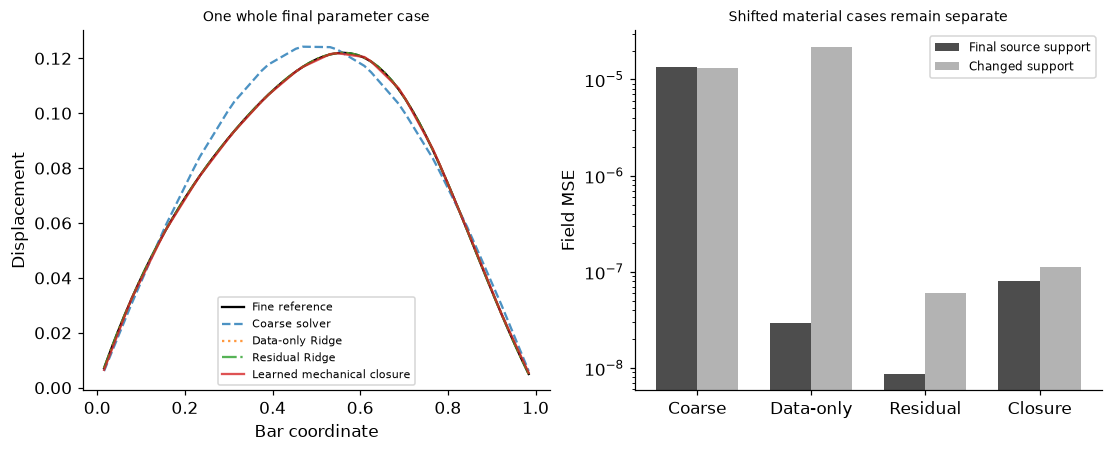

In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.linear_model import Ridge
def case_inputs(n,shift=False):
    return np.column_stack([rng.uniform(.45,.75,n) if shift else rng.uniform(-.25,.25,n),rng.uniform(1.2,1.8,n) if shift else rng.uniform(-1,1,n),rng.uniform(.7,1.3,n),rng.uniform(-.3,.3,n)])
cases=np.vstack([case_inputs(56),case_inputs(16,True)])
def incidence(n):
    D=np.zeros((n+1,n))
    for i in range(n):D[i,i]+=1;D[i+1,i]-=1
    return D
def solve_case(case,n,correct=True):
    a,b,p,c=case;h=1/(n+1);x=np.arange(1,n+1)*h;edge=(np.arange(n+1)+.5)*h;conductance=(1+a*edge)*np.exp((.35+.14*b)*np.sin(2*np.pi*edge)) if correct else 1+a*edge;D=incidence(n);K=D.T@(conductance[:,None]*D)/h**2;load=p*(np.sin(np.pi*x)+c*np.sin(2*np.pi*x));return x,np.linalg.solve(K,load)
grid=np.arange(1,64)/64;fine=np.stack([solve_case(c,63)[1] for c in cases]);coarse=[]
for case in cases:
    x,u=solve_case(case,12,False);coarse.append(np.interp(grid,np.r_[0,x,1],np.r_[0,u,0]))
coarse=np.stack(coarse);features=np.column_stack([cases,coarse]);predictions={'Coarse solver':coarse};selection=[]
for family,response in [('Data-only Ridge',fine),('Residual Ridge',fine-coarse)]:
    choices=[]
    for alpha in [.001,.1,10.]:
        model=make_pipeline(PolynomialFeatures(2,include_bias=False),StandardScaler(),Ridge(alpha=alpha));model.fit(features[:32] if family=='Residual Ridge' else cases[:32],response[:32]);input_all=features if family=='Residual Ridge' else cases;pred=model.predict(input_all)+(coarse if family=='Residual Ridge' else 0);score=float(np.mean((pred[32:40]-fine[32:40])**2));choices.append((score,alpha,pred));selection.append({'model':family,'alpha':alpha,'development_MSE':score})
    predictions[family]=min(choices,key=lambda z:z[0])[2]
n=12;h=1/(n+1);xc=torch.tensor(np.arange(1,n+1)*h);edge=torch.tensor((np.arange(n+1)+.5)*h);D=torch.tensor(incidence(n));C=torch.tensor(cases);loads=C[:,2,None]*(torch.sin(torch.pi*xc)[None,:]+C[:,3,None]*torch.sin(2*torch.pi*xc)[None,:]);target_coarse=torch.tensor(np.stack([np.interp(xc.numpy(),np.r_[0,grid,1],np.r_[0,u,0]) for u in fine]));gamma=nn.Parameter(torch.zeros(2))
def closure_output():
    conductance=(1+C[:,0,None]*edge)*torch.exp((gamma[0]+gamma[1]*C[:,1,None])*torch.sin(2*torch.pi*edge));K=torch.einsum('ei,be,ej->bij',D,conductance,D)/h**2;return torch.linalg.solve(K,loads.unsqueeze(-1)).squeeze(-1),K,conductance
opt=torch.optim.Adam([gamma],lr=.03)
for step in range(1000):
    opt.zero_grad();u,K,k=closure_output();loss=(u[:32]-target_coarse[:32]).square().mean();loss.backward();opt.step()
u,K,k=closure_output();closure=np.stack([np.interp(grid,np.r_[0,xc.numpy(),1],np.r_[0,v,0]) for v in u.detach().numpy()]);predictions['Learned mechanical closure']=closure
# Parameter sensitivity of a differentiable linear solve, checked on source cases only.
objective=u[:32].square().mean();auto=float(torch.autograd.grad(objective,gamma)[0][0]);orig=gamma.detach().clone();eps=1e-5
with torch.no_grad():
    gamma[0]+=eps;plus=float(closure_output()[0][:32].square().mean());gamma.copy_(orig);gamma[0]-=eps;minus=float(closure_output()[0][:32].square().mean());gamma.copy_(orig)
fd=(plus-minus)/(2*eps);assert abs(auto-fd)<1e-8
torch.testing.assert_close(torch.einsum('bij,bj->bi',K,u),loads,atol=1e-12,rtol=1e-12);assert float(k.min().detach())>0
reference_checks=[]
for index in [0,40,56]:
    xf,uf=solve_case(cases[index],127);on_grid=np.interp(grid,np.r_[0,xf,1],np.r_[0,uf,0]);reference_checks.append({'case_index':index,'63_vs_127_grid_RMS':float(np.sqrt(np.mean((fine[index]-on_grid)**2)))})
rows=[]
for name,pred in predictions.items():rows.append({'model':name,'source_MSE':float(np.mean((pred[:32]-fine[:32])**2)),'development_MSE':float(np.mean((pred[32:40]-fine[32:40])**2)),'final_MSE':float(np.mean((pred[40:56]-fine[40:56])**2)),'changed_support_MSE':float(np.mean((pred[56:]-fine[56:])**2))})
RESULTS.update(comparisons=rows,ridge_candidates=selection,case_counts=[32,8,16,16],fine_interior_cells=63,coarse_interior_cells=12,reference_refinement=reference_checks,learned_closure_coefficients=gamma.detach().tolist(),generating_closure_coefficients=[.35,.14],closure_gradient_check={'autograd':auto,'finite_difference':fd,'absolute_difference':abs(auto-fd)},source_fine_solve_labels=32,development_fine_solve_labels=8,final_and_shifted_assessment_fine_solves=32,reference_refinement_extra_solves=3,minimum_closure_conductance=float(k.min().detach()),max_coarse_equilibrium_error=float((torch.einsum('bij,bj->bi',K,u)-loads).abs().max().detach()));display(pd.DataFrame(rows));print('Fitted closure:',gamma.detach().tolist())
fig,axes=plt.subplots(1,2,figsize=(10,4));j=40;axes[0].plot(grid,fine[j],'k-',label='Fine reference')
for name,style in zip(predictions,['--',':','-.','-']):axes[0].plot(grid,predictions[name][j],style,label=name,alpha=.8)
axes[0].set(xlabel='Bar coordinate',ylabel='Displacement',title='One whole final parameter case');axes[0].legend(fontsize=7);xx=np.arange(len(rows));axes[1].bar(xx-.18,[r['final_MSE'] for r in rows],.36,color='.3',label='Final source support');axes[1].bar(xx+.18,[r['changed_support_MSE'] for r in rows],.36,color='.7',label='Changed support');axes[1].set(yscale='log',xticks=xx,xticklabels=['Coarse','Data-only','Residual','Closure'],ylabel='Field MSE',title='Shifted material cases remain separate');axes[1].legend(fontsize=8);plt.show()


<a id="hybrid-limits"></a>
 ## A corrected response and a corrected operator enforce different things
 Residual Ridge adds a predicted field discrepancy to the available coarse solve; its fitted output need not satisfy equilibrium. The learned closure changes a positive conductance field before solving the coarse equations, preserving their discrete balance. Its two-parameter spatial modulation is deliberately well matched to the generator, and is a parametric closure rather than a general neural constitutive law. Coarse discretization still causes error and can bias recovered coefficients. Both Ridge models get three regularization choices and select independently; the closure has a different capacity, optimization recipe and mechanistic prior. No measured speedup is asserted. Fine-solve counts describe this finite data-generation budget, not industrial simulation cost. A deployment must count required coarse calls, training high-fidelity cases and independent validation evidence.


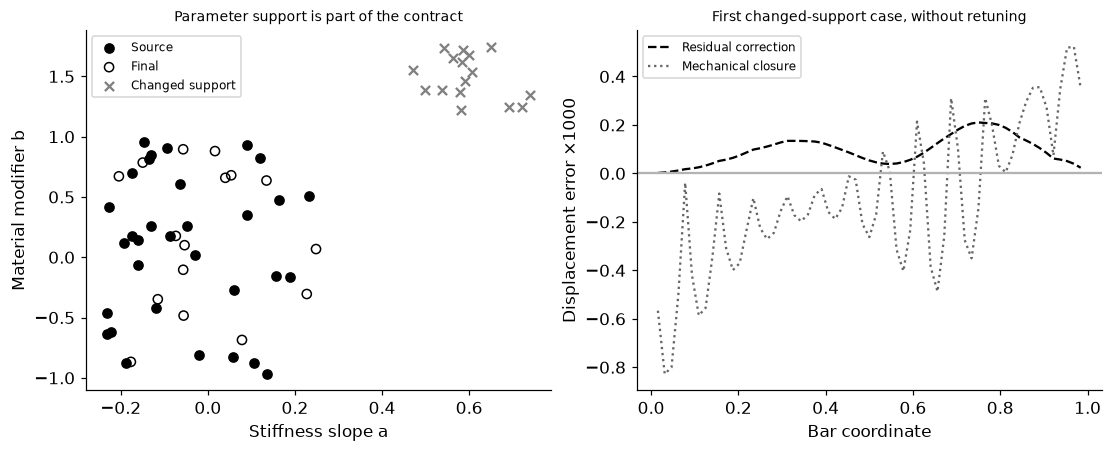

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].scatter(cases[:32,0],cases[:32,1],color='black',label='Source');axes[0].scatter(cases[40:56,0],cases[40:56,1],facecolors='none',edgecolors='black',label='Final');axes[0].scatter(cases[56:,0],cases[56:,1],marker='x',color='.5',label='Changed support');axes[0].set(xlabel='Stiffness slope a',ylabel='Material modifier b',title='Parameter support is part of the contract');axes[0].legend(fontsize=8)
axes[1].plot(grid,(predictions['Residual Ridge'][56]-fine[56])*1000,'--',color='black',label='Residual correction');axes[1].plot(grid,(closure[56]-fine[56])*1000,':',color='.4',label='Mechanical closure');axes[1].axhline(0,color='.7');axes[1].set(xlabel='Bar coordinate',ylabel='Displacement error ×1000',title='First changed-support case, without retuning');axes[1].legend(fontsize=8);plt.show()
assert len(rows)==4 and all(np.isfinite(r['changed_support_MSE']) for r in rows)


In [4]:
summary={'example_id':'code_131','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['native coarse and fine mechanical solves', 'actual residual-correction Ridge', 'data-only comparison with matched case selection', 'differentiable positive-conductance closure', 'whole-case and changed-support assessment'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["native coarse and fine mechanical solves", "actual residual-correction Ridge", "data-only comparison with matched case selection", "differentiable positive-conductance closure", "whole-case and changed-support assessment"], "elapsed_seconds": 1.772, "example_id": "code_131", "hardware": "Darwin arm64 CPU", "results": {"case_counts": [32, 8, 16, 16], "closure_gradient_check": {"absolute_difference": 3.881443777498106e-15, "autograd": -0.001081243388793905, "finite_difference": -0.0010812433887900236}, "coarse_interior_cells": 12, "comparisons": [{"changed_support_MSE": 1.3184459223268153e-05, "development_MSE": 1.2735702856030234e-05, "final_MSE": 1.3561000452297638e-05, "model": "Coarse solver", "source_MSE": 1.4167747638724017e-05}, {"changed_support_MSE": 2.191876470997815e-05, "development_MSE": 2.1299866147397265e-08, "final_MSE": 2.924282303986949e-08, "model": "Data-only Ridge", "source_MSE": 2.2652271029950956e-09}, {"changed_su